In [ ]:
!git clone https://github.com/afridorian/semantic-change-over-time.git

Cloning into 'semantic-change-over-time'...
remote: Enumerating objects: 4771, done.
remote: Counting objects: 100% (4771/4771), done.
remote: Compressing objects: 100% (2438/2438), done.
remote: Total 4771 (delta 2324), reused 4771 (delta 2324), pack-reused 0 (from 0)
Receiving objects: 100% (4771/4771), 31.13 MiB | 10.61 MiB/s, done.
Resolving deltas: 100% (2324/2324), done.


## creating dataframe

In [ ]:
import pandas as pd

folder = "semantic-change-over-time/data/raw/development-swedish/"
df = pd.read_json(folder + "usages.jsonl", lines=True)
df.head()

,word,sentence_id,text,pos,period_label,start,end,year
0,kvinna,137d9286_62_69,nesliga lif medelst sjelfmord ; och ett stort ...,NN,1880-1883,62,69,1883
1,kvinna,b382a5e9_92_98,"— Jag sov ; jag väcktes av en kylande känsla ,...",NN,1912-1915,92,98,1914
2,kvinna,28ffffe7_42_50,"orden , så mycken fasthet öfver den gamla kvin...",NN,1880-1883,42,50,1883
3,kvinna,3754909a_117_124,Dessa klubbar ha anordnat sällskapliga samkväm...,NN,1912-1915,117,124,1913
4,kvinna,59ebb00_32_39,Den avvisningshotade eritranska kvinnan Abiba ...,NN,2006-2007,32,39,2007


#### showing shape and counts

In [ ]:
print(df.shape)
df["word"].value_counts()

(1983, 8)


,count
word,
motiv,291
kvinna,290
herre,283
fru,274
fröken,174
förort,150
exportera,149
dumpa,145
suga,129


#### grabbing word from sentence

In [ ]:
first = df.iloc[0]
text = first["text"]
s = first["start"]
e = first["end"]

print(text) #full sentence
print(text[s:e]) #just word

nesliga lif medelst sjelfmord ; och ett stort antal olyckliga kvinnor , sorn sökt fly undan eländet , ha fallit i „mordeHglarnes4 händer , och deras ben vittra öfver allt i Utahs solbrända dalar .
kvinnor


#### quickly seeing how often word falls into time period

In [ ]:
pd.crosstab(df["word"], df["period_label"])

period_label,1880-1883,1888-1891,1896-1899,1904-1907,1912-1915,2006-2007,2010-2011,2014-2015,2018-2019,2022-2023
word,,,,,,,,,,
dumpa,0,0,0,0,0,30,28,27,30,30
exportera,0,0,0,0,0,30,30,29,30,30
fru,29,26,23,18,28,30,30,30,30,30
fröken,28,23,30,23,23,4,9,23,7,4
förort,0,0,0,0,0,30,30,30,30,30
herre,28,24,27,27,28,29,30,30,30,30
kvinna,30,25,29,27,29,30,30,30,30,30
motiv,29,27,29,30,30,29,29,29,29,30
skär,19,14,24,16,25,0,0,0,0,0


## baselines, grabbing grading scale

In [ ]:
!git clone https://github.com/ChangeIsKey/semeval2027-task3.git
!git clone https://github.com/hhromic/python-bcubed.git
!cp -r python-bcubed/bcubed semeval2027-task3/
!mkdir -p gold/SV
!cp semantic-change-over-time/data/raw/development-swedish/subtask*.jsonl gold/SV/

fatal: destination path 'semeval2027-task3' already exists and is not an empty directory.
fatal: destination path 'python-bcubed' already exists and is not an empty directory.


#### compressing

In [ ]:
!zip -j example.zip semantic-change-over-time/data/example-submission-format/*.jsonl

updating: SV_subtask1.jsonl (deflated 86%)
updating: SV_subtask2.jsonl (deflated 83%)


#### grading

In [ ]:
!python semeval2027-task3/evaluation.py example.zip gold -o example_results.json

{
  "results": {
    "subtask1a": {
      "SV": {
        "precision": 0.6742509015772573,
        "recall": 0.11548613436982033,
        "fcubed": 0.18905192333333407
      },
      "average": {
        "precision": 0.6742509015772573,
        "recall": 0.11548613436982033,
        "fcubed": 0.18905192333333407
      }
    },
    "subtask1b": {
      "SV": 0.15291845625518283,
      "average": 0.15291845625518283
    },
    "subtask2": {
      "SV": 0.4422180107796946,
      "average": 0.4422180107796946
    }
  },
  "errors": [],
  "logs": [
    {
      "level": "info",
      "message": "Found 2 files in submission."
    },
    {
      "level": "info",
      "language": "SV",
      "subtask": "subtask1",
      "message": "Evaluation completed successfully."
    },
    {
      "level": "info",
      "language": "SV",
      "subtask": "subtask2",
      "message": "Evaluation completed successfully."
    }
  ]
}


### subtask 1 guess

In [ ]:
guess1 = df[["word", "period_label", "sentence_id"]].copy()
guess1["label"] = [[0]] * len(guess1)
guess1.to_json("SV_subtask1.jsonl", orient="records", lines=True)
guess1.head()

,word,period_label,sentence_id,label
0,kvinna,1880-1883,137d9286_62_69,[0]
1,kvinna,1912-1915,b382a5e9_92_98,[0]
2,kvinna,1880-1883,28ffffe7_42_50,[0]
3,kvinna,1912-1915,3754909a_117_124,[0]
4,kvinna,2006-2007,59ebb00_32_39,[0]


### subtask 2 guess (everything guessed as yes... gets 1)

In [ ]:
guess2 = df[["word", "sentence_id"]].copy()
guess2["label"] = 1
guess2.to_json("SV_subtask2.jsonl", orient="records", lines=True)
guess2.head()

,word,sentence_id,label
0,kvinna,137d9286_62_69,1
1,kvinna,b382a5e9_92_98,1
2,kvinna,28ffffe7_42_50,1
3,kvinna,3754909a_117_124,1
4,kvinna,59ebb00_32_39,1


### grading to see how good the guesses are

In [ ]:
import sys
from pathlib import Path
sys.path.append("semeval2027-task3")
from evaluation import evaluate_subtask1, evaluate_subtask2

score_1a, score_1b = evaluate_subtask1(Path("gold/SV/subtask1.jsonl"), Path("SV_subtask1.jsonl"))
score_2 = evaluate_subtask2(Path("gold/SV/subtask2.jsonl"), Path("SV_subtask2.jsonl"))

print("1a:", score_1a["fcubed"])
print("1b:", score_1b)
print("2:", score_2)

/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


1a: 0.7563415432223628
1b: 0
2: 0.23581479994186685


## Subtask 1a: Grouping word usages by meaning (Andrea testing)

###Attempt 1: XLM-RoBERTa

In [ ]:
%pip install -q transformers sentencepiece scikit-learn

####Load XLM-RoBERTa and its tokenizer for word embeddings.

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModel

if torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"

model_name = "FacebookAI/xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=True)

model = AutoModel.from_pretrained(model_name).to(device).eval()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


####Get a vector for each target word using its sentence context.

In [ ]:
def get_word_vector(row):
    sentence = row["text"]
    start = int(row["start"])
    end = int(row["end"])

    encoded = tokenizer(
        sentence,
        return_offsets_mapping=True,
        return_tensors="pt"
    )

    offsets = encoded.pop("offset_mapping")[0].tolist()

    target_tokens = []
    for i, (token_start, token_end) in enumerate(offsets):
        if token_end > token_start and token_start < end and token_end > start:
            target_tokens.append(i)

    if not target_tokens:
        raise ValueError(f"Target word not found: {row['sentence_id']}")

    encoded = encoded.to(device)

    with torch.no_grad():
        output = model(**encoded)

    target_vectors = output.last_hidden_state[0, target_tokens]
    vector = target_vectors.mean(dim=0)

    return vector.cpu().numpy()

####Start by extracting vectors for all usages of kvinna.

In [ ]:
import numpy as np
from tqdm.auto import tqdm

word_data = df.loc[df["word"] == "kvinna"].copy()

vectors = []
for _, row in tqdm(word_data.iterrows(), total=len(word_data)):
    vectors.append(get_word_vector(row))

word_vectors = np.stack(vectors)

  0%|          | 0/290 [00:00<?, ?it/s]

####Try 2–6 clusters and select the number with the highest silhouette score.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize

scaled_vectors = normalize(word_vectors)

scores = {}
cluster_labels = {}

for k in range(2, 7):
    labels = KMeans(
        n_clusters=k, n_init=20, random_state=42
    ).fit_predict(scaled_vectors)

    scores[k] = silhouette_score(scaled_vectors, labels)
    cluster_labels[k] = labels

best_k = max(scores, key=scores.get)
word_data["cluster"] = cluster_labels[best_k]

word_data["cluster"].value_counts()

,count
cluster,
1,108
5,74
4,69
3,26
2,8
0,5


####Compare our clusters with the single-cluster baseline using BCubed F1.

In [ ]:
from pathlib import Path
from evaluation import evaluate_subtask1

word_gold = pd.read_json("gold/SV/subtask1.jsonl", lines=True)
word_gold = word_gold.loc[word_gold["word"] == "kvinna"]
word_gold.to_json("kvinna_gold.jsonl", orient="records", lines=True)

predictions = word_data[["word", "period_label", "sentence_id"]].copy()
predictions["label"] = [[int(label)] for label in word_data["cluster"]]
predictions.to_json("kvinna_clusters.jsonl", orient="records", lines=True)

baseline = predictions.copy()
baseline["label"] = [[0] for _ in range(len(baseline))]
baseline.to_json("kvinna_baseline.jsonl", orient="records", lines=True)

gold_path = Path("kvinna_gold.jsonl")

for method in ["baseline", "clusters"]:
    prediction_path = Path(f"kvinna_{method}.jsonl")
    result, _ = evaluate_subtask1(gold_path, prediction_path)
    print(method, "BCubed F1:", result["fcubed"])

baseline BCubed F1: 0.7867069117564337
clusters BCubed F1: 0.4116573936071721


/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


###Attempt 2: XL-LEXEME

####Load XL-LEXEME and its tokenizer for the second clustering attempt.

In [ ]:
lexeme_name = "pierluigic/xl-lexeme"

lexeme_tokenizer = AutoTokenizer.from_pretrained(
    lexeme_name, use_fast=True
)
lexeme_model = AutoModel.from_pretrained(lexeme_name).to(device).eval()

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

####Mark the target word and create a vector for its meaning in context.

In [ ]:
def get_lexeme_vector(row):
    text = row["text"]
    start = int(row["start"])
    end = int(row["end"])

    marked_text = f"{text[:start]}<t>{text[start:end]}</t>{text[end:]}"
    encoded = lexeme_tokenizer(marked_text, return_tensors="pt")

    if encoded["input_ids"].shape[1] > 512:
        raise ValueError("Sentence needs a shorter context window.")

    encoded = encoded.to(device)

    with torch.no_grad():
        output = lexeme_model(**encoded)

    valid_tokens = encoded["attention_mask"][0].bool()
    token_vectors = output.last_hidden_state[0][valid_tokens]
    vector = token_vectors.mean(dim=0)

    return vector.cpu().numpy()

####Extract XL-LEXEME vectors for the same word used in the first attempt.

In [ ]:
lexeme_data = df.loc[df["word"] == "kvinna"].copy()

lexeme_vectors = lexeme_data.apply(get_lexeme_vector, axis=1)
lexeme_vectors = np.stack(lexeme_vectors.to_list())

lexeme_vectors.shape

(290, 1024)

####Try 2–6 clusters with XL-LEXEME and select the highest silhouette score.

In [ ]:
lexeme_scaled = normalize(lexeme_vectors)

lexeme_scores = {}
lexeme_labels = {}

for k in range(2, 7):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = kmeans.fit_predict(lexeme_scaled)

    lexeme_scores[k] = silhouette_score(lexeme_scaled, labels)
    lexeme_labels[k] = labels

lexeme_best_k = max(lexeme_scores, key=lexeme_scores.get)
lexeme_data["cluster"] = lexeme_labels[lexeme_best_k]

lexeme_data["cluster"].value_counts()

,count
cluster,
0,170
1,120


####Compare both models with the single-cluster baseline using BCubed F1.

In [ ]:
lexeme_predictions = lexeme_data[
    ["word", "period_label", "sentence_id"]
].copy()

lexeme_predictions["label"] = [
    [int(label)] for label in lexeme_data["cluster"]
]
lexeme_predictions.to_json(
    "kvinna_lexeme_clusters.jsonl", orient="records", lines=True
)

prediction_files = {
    "Baseline": "kvinna_baseline.jsonl",
    "XLM-RoBERTa": "kvinna_clusters.jsonl",
    "XL-LEXEME": "kvinna_lexeme_clusters.jsonl"
}

for method, filename in prediction_files.items():
    result, _ = evaluate_subtask1(
        Path("kvinna_gold.jsonl"), Path(filename)
    )
    print(method, "BCubed F1:", result["fcubed"])

/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


Baseline BCubed F1: 0.7867069117564337
XLM-RoBERTa BCubed F1: 0.4116573936071721
XL-LEXEME BCubed F1: 0.6175874776851439


####Use seven words to tune our approach and reserve three for evaluation.

In [ ]:
tuning_words = [
    "motiv", "kvinna", "fru", "fröken", "förort", "skär", "suga"
]

heldout_words = ["dumpa", "exportera", "herre"]

####Create word vectors for the tuning words, reusing the existing kvinna vectors.

In [ ]:
data_by_word = {"kvinna": lexeme_data.copy()}
vectors_by_word = {"kvinna": lexeme_vectors.copy()}

for word in tqdm(tuning_words):
    if word == "kvinna":
        continue

    word_rows = df.loc[df["word"] == word].copy()
    vectors = []

    for _, row in word_rows.iterrows():
        vectors.append(get_lexeme_vector(row))

    data_by_word[word] = word_rows
    vectors_by_word[word] = np.stack(vectors)

  0%|          | 0/7 [00:00<?, ?it/s]

####Compare different numbers of clusters on the tuning words using silhouette score and BCubed F1.

In [ ]:
gold_data = pd.read_json("gold/SV/subtask1.jsonl", lines=True)

tuning_results = []
labels_by_word = {}

for word in tuning_words:
    word_rows = data_by_word[word]
    vectors = normalize(vectors_by_word[word])
    labels_by_word[word] = {}

    word_gold = gold_data.loc[gold_data["word"] == word]
    word_gold.to_json("tuning_gold.jsonl", orient="records", lines=True)

    for k in range(1, 7):
        if k == 1:
            labels = np.zeros(len(word_rows), dtype=int)
            silhouette = np.nan
        else:
            labels = KMeans(
                n_clusters=k, n_init=20, random_state=42
            ).fit_predict(vectors)
            silhouette = silhouette_score(vectors, labels)

        labels_by_word[word][k] = labels

        predictions = word_rows[
            ["word", "period_label", "sentence_id"]
        ].copy()
        predictions["label"] = [[int(label)] for label in labels]
        predictions.to_json(
            "tuning_predictions.jsonl", orient="records", lines=True
        )

        result, _ = evaluate_subtask1(
            Path("tuning_gold.jsonl"),
            Path("tuning_predictions.jsonl")
        )

        tuning_results.append({
            "word": word,
            "k": k,
            "silhouette": silhouette,
            "BCubed F1": result["fcubed"]
        })

tuning_results = pd.DataFrame(tuning_results)
tuning_results.pivot(index="word", columns="k", values="BCubed F1")

/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/content/semeval2027

k,1,2,3,4,5,6
word,,,,,,
fru,0.895900,0.691004,0.640895,0.458015,0.380633,0.387797
fröken,0.818799,0.829544,0.623511,0.524030,0.499612,0.433460
förort,0.804315,0.720264,0.502693,0.480100,0.394018,0.341021
kvinna,0.786707,0.617587,0.495514,0.421590,0.369818,0.325648
motiv,0.782268,0.947544,0.815615,0.620090,0.626407,0.545309
skär,0.545178,0.590782,0.516143,0.489212,0.480233,0.462864
suga,0.320029,0.420562,0.538581,0.569798,0.599675,0.618297


####Tune a silhouette threshold to decide when to split a word’s usages into multiple clusters.

In [ ]:
single_cluster = tuning_results.loc[
    tuning_results["k"] == 1
].set_index("word")

multiple_clusters = tuning_results.loc[tuning_results["k"] > 1]
best_splits = multiple_clusters.loc[
    multiple_clusters.groupby("word")["silhouette"].idxmax()
].set_index("word")

threshold_results = []

for threshold in np.arange(0, 0.55, 0.05):
    scores = []
    words_split = 0

    for word in tuning_words:
        split = best_splits.loc[word]

        if split["silhouette"] >= threshold:
            scores.append(split["BCubed F1"])
            words_split += 1
        else:
            scores.append(single_cluster.loc[word, "BCubed F1"])

    threshold_results.append({
        "threshold": round(float(threshold), 2),
        "mean_BCubed_F1": np.mean(scores),
        "words_split": words_split
    })

threshold_results = pd.DataFrame(threshold_results)

print("Single-cluster mean:", single_cluster["BCubed F1"].mean())
threshold_results.sort_values("mean_BCubed_F1", ascending=False)

Single-cluster mean: 0.7075995648031598


,threshold,mean_BCubed_F1,words_split
7,0.35,0.745572,2
8,0.40,0.731210,1
9,0.45,0.731210,1
6,0.30,0.717836,4
4,0.20,0.712344,6
10,0.50,0.707600,0
5,0.25,0.705829,5
2,0.10,0.688184,7
1,0.05,0.688184,7
0,0.00,0.688184,7


####Use the selected threshold of 0.35 for evaluation on three held-out words.

In [ ]:
selected_threshold = 0.35

for word in tqdm(heldout_words):
    word_rows = df.loc[df["word"] == word].copy()
    vectors = []

    for _, row in word_rows.iterrows():
        vectors.append(get_lexeme_vector(row))

    data_by_word[word] = word_rows
    vectors_by_word[word] = np.stack(vectors)

  0%|          | 0/3 [00:00<?, ?it/s]

####Compare our selected clustering rule with the single-cluster baseline on the held-out words.

In [ ]:
heldout_results = []

for word in heldout_words:
    word_rows = data_by_word[word]
    vectors = normalize(vectors_by_word[word])

    best_score = -1
    best_k = 1
    best_labels = None

    for k in range(2, 7):
        labels = KMeans(
            n_clusters=k, n_init=20, random_state=42
        ).fit_predict(vectors)

        score = silhouette_score(vectors, labels)

        if score > best_score:
            best_score = score
            best_k = k
            best_labels = labels

    if best_score < selected_threshold:
        best_k = 1
        best_labels = np.zeros(len(word_rows), dtype=int)

    word_gold = gold_data.loc[gold_data["word"] == word]
    word_gold.to_json(
        "heldout_gold.jsonl", orient="records", lines=True
    )

    predictions = word_rows[
        ["word", "period_label", "sentence_id"]
    ].copy()

    scores = {}
    for method in ["baseline", "model"]:
        if method == "baseline":
            labels = np.zeros(len(word_rows), dtype=int)
        else:
            labels = best_labels

        predictions["label"] = [[int(label)] for label in labels]
        predictions.to_json(
            "heldout_predictions.jsonl", orient="records", lines=True
        )

        result, _ = evaluate_subtask1(
            Path("heldout_gold.jsonl"),
            Path("heldout_predictions.jsonl")
        )
        scores[method] = result["fcubed"]

    heldout_results.append({
        "word": word,
        "selected_k": best_k,
        "baseline_F1": scores["baseline"],
        "model_F1": scores["model"],
        "difference": scores["model"] - scores["baseline"]
    })

heldout_results = pd.DataFrame(heldout_results)
display(heldout_results)
heldout_results[["baseline_F1", "model_F1"]].mean()

/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


,word,selected_k,baseline_F1,model_F1,difference
0,dumpa,2,0.849245,0.874051,0.024806
1,exportera,2,0.946122,0.980765,0.034643
2,herre,1,0.814852,0.814852,0.000000


,0
baseline_F1,0.870073
model_F1,0.889889


####Apply the selected clustering rule to all development words and save the predictions.

In [ ]:
all_predictions = []

for word in sorted(data_by_word):
    word_rows = data_by_word[word]
    vectors = normalize(vectors_by_word[word])

    best_score = -1
    best_labels = None

    for k in range(2, 7):
        labels = KMeans(
            n_clusters=k, n_init=20, random_state=42
        ).fit_predict(vectors)

        score = silhouette_score(vectors, labels)

        if score > best_score:
            best_score = score
            best_labels = labels

    if best_score < selected_threshold:
        best_labels = np.zeros(len(word_rows), dtype=int)

    predictions = word_rows[
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in best_labels]

    all_predictions.append(predictions)

development_predictions = pd.concat(all_predictions, ignore_index=True)
development_predictions.to_json(
    "development_subtask1.jsonl", orient="records", lines=True
)

####Evaluate sense clustering and changes in sense frequencies across time.

In [ ]:
clustering_scores, change_score = evaluate_subtask1(
    Path("gold/SV/subtask1.jsonl"),
    Path("development_subtask1.jsonl")
)

print("1a BCubed precision:", clustering_scores["precision"])
print("1a BCubed recall:", clustering_scores["recall"])
print("1a BCubed F1:", clustering_scores["fcubed"])
print("1b Spearman correlation:", change_score)

1a BCubed precision: 0.6993123481208025
1a BCubed recall: 0.9638035258592375
1a BCubed F1: 0.7888673121993135
1b Spearman correlation: 0.13836731736648875


In [ ]:
development_baseline = development_predictions.copy()
development_baseline["label"] = [
    [0] for _ in range(len(development_baseline))
]

development_baseline.to_json(
    "development_baseline.jsonl", orient="records", lines=True
)

baseline_scores, baseline_change = evaluate_subtask1(
    Path("gold/SV/subtask1.jsonl"),
    Path("development_baseline.jsonl")
)

print("Baseline 1a F1:", baseline_scores["fcubed"])
print("Our model 1a F1:", clustering_scores["fcubed"])

Baseline 1a F1: 0.7563415432223628
Our model 1a F1: 0.7888673121993135


/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


####Compare silhouette thresholds for sense clustering and semantic change on the tuning words.

In [ ]:
tuning_gold = gold_data.loc[gold_data["word"].isin(tuning_words)]
tuning_gold.to_json(
    "tuning_all_gold.jsonl", orient="records", lines=True
)

threshold_comparison = []

for threshold in np.arange(0, 0.55, 0.05):
    prediction_parts = []

    for word in tuning_words:
        split = best_splits.loc[word]

        if split["silhouette"] >= threshold:
            k = int(split["k"])
        else:
            k = 1

        labels = labels_by_word[word][k]

        predictions = data_by_word[word][
            ["word", "period_label", "sentence_id"]
        ].copy()
        predictions["label"] = [[int(label)] for label in labels]
        prediction_parts.append(predictions)

    predictions = pd.concat(prediction_parts, ignore_index=True)
    predictions.to_json(
        "threshold_predictions.jsonl", orient="records", lines=True
    )

    clustering, change = evaluate_subtask1(
        Path("tuning_all_gold.jsonl"),
        Path("threshold_predictions.jsonl")
    )

    threshold_comparison.append({
        "threshold": round(float(threshold), 2),
        "1a_F1": clustering["fcubed"],
        "1b_Spearman": change
    })

threshold_comparison = pd.DataFrame(threshold_comparison)
threshold_comparison

/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


,threshold,1a_F1,1b_Spearman
0,0.00,0.688184,0.322703
1,0.05,0.688184,0.322703
2,0.10,0.688184,0.322703
3,0.15,0.688184,0.322703
4,0.20,0.712344,0.454947
5,0.25,0.705829,0.203993
6,0.30,0.717836,0.227977
7,0.35,0.745572,0.202903
8,0.40,0.731210,0.005521
9,0.45,0.731210,0.005521


####Evaluate the threshold of 0.20 on the three reserved words.

In [ ]:
candidate_parts = []

for word in heldout_words:
    vectors = normalize(vectors_by_word[word])
    best_score = -1
    best_labels = None

    for k in range(2, 7):
        labels = KMeans(
            n_clusters=k, n_init=20, random_state=42
        ).fit_predict(vectors)

        score = silhouette_score(vectors, labels)

        if score > best_score:
            best_score = score
            best_labels = labels

    if best_score < 0.20:
        best_labels = np.zeros(len(vectors), dtype=int)

    predictions = data_by_word[word][
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in best_labels]
    candidate_parts.append(predictions)

candidate_predictions = pd.concat(candidate_parts, ignore_index=True)
candidate_predictions.to_json(
    "candidate_020.jsonl", orient="records", lines=True
)

heldout_gold = gold_data.loc[gold_data["word"].isin(heldout_words)]
heldout_gold.to_json(
    "heldout_all_gold.jsonl", orient="records", lines=True
)

scores, change = evaluate_subtask1(
    Path("heldout_all_gold.jsonl"),
    Path("candidate_020.jsonl")
)

print("Threshold 0.20 — 1a F1:", scores["fcubed"])
print("Threshold 0.20 — 1b Spearman:", change)

Threshold 0.20 — 1a F1: 0.8268412439973272
Threshold 0.20 — 1b Spearman: 0.0036877695963759122


####Inspect how the selected clusters group usages of suga.

In [ ]:
word = "suga"
selected_k = int(best_splits.loc[word, "k"])

examples = data_by_word[word].copy()
examples["cluster"] = labels_by_word[word][selected_k]

for cluster, rows in examples.groupby("cluster"):
    print(f"\nCluster {cluster}")
    for _, row in rows.head(4).iterrows():
        print(f"{row['year']}: {row['text']}")


Cluster 0
2022: – Vi kunde suga upp motsvarande mängd men då var det uppblandat med vatten så vi behöver undersöka hur mycket som finns kvar i marken och vart det tar vägen , säger Morgan Palmquist på räddningstjänsten .
2015: De har använt livs levande svärmare av den nordamerikanska arten Manduca sexta som försöksdjur och låtit dem suga sockerlösning ur konstgjorda blommor som monterats på en robotarm .
2010: Längre livslängd , mer energi , yngre hy och en mängd andra positiva effekter utlovas om man suger i sig lite av den 89-procentiga syrgasen .
2010: Men på söndagen meddelade BP att man nu har lyckats suga upp läckande olja genom ett rör som man satte dit på eftermiddagen .

Cluster 1
2007: På frågan om vi får se henne i Melodifestivalsammanhang igen svarar Sarah : ” Jag vet inte , det här är så stort så jag vill suga på den här karamellen ett tag .
2019: Det kunde och borde gynna spelet men just nu suger det bara livet ur sporten ” , skriver Gary Lineker , som har ett förflutet

In [ ]:
examples = data_by_word["suga"].copy()
examples["cluster"] = labels_by_word["suga"][6]

for cluster, rows in examples.groupby("cluster"):
    print(f"\nCluster {cluster} — {len(rows)} usages")
    for _, row in rows.head(3).iterrows():
        print(f"{row['year']}: {row['text']}")


Cluster 0 — 13 usages
2007: På frågan om vi får se henne i Melodifestivalsammanhang igen svarar Sarah : ” Jag vet inte , det här är så stort så jag vill suga på den här karamellen ett tag .
2011: Vi kände oss väldigt väl mottagna i Sverige och hade en fantastisk vecka i Stockholm även om den sög musten ur mig , säger Vargas Llosa i ett pressmeddelande .
2019: Jag känner fortfarande en stor kärlek till sporten men ledarskapet och förbundets hantering sög till slut all energi och jag tappade gnistan till min egen pingis .

Cluster 1 — 30 usages
2015: De har använt livs levande svärmare av den nordamerikanska arten Manduca sexta som försöksdjur och låtit dem suga sockerlösning ur konstgjorda blommor som monterats på en robotarm .
2010: Längre livslängd , mer energi , yngre hy och en mängd andra positiva effekter utlovas om man suger i sig lite av den 89-procentiga syrgasen .
2011: Många barn tycker ju om smycken , speciellt flickor , och det finns ju väldigt mycket billiga smycken , som 

####Compare cluster counts and silhouette thresholds on the tuning words.

In [ ]:
selection_results = []

tuning_lookup = tuning_results.set_index(["word", "k"])

for k in range(2, 7):
    for threshold in [0.0, 0.20, 0.35]:
        prediction_parts = []

        for word in tuning_words:
            silhouette = tuning_lookup.loc[(word, k), "silhouette"]

            if silhouette >= threshold:
                labels = labels_by_word[word][k]
            else:
                labels = labels_by_word[word][1]

            predictions = data_by_word[word][
                ["word", "period_label", "sentence_id"]
            ].copy()
            predictions["label"] = [
                [int(label)] for label in labels
            ]
            prediction_parts.append(predictions)

        predictions = pd.concat(prediction_parts, ignore_index=True)
        predictions.to_json(
            "selection_predictions.jsonl",
            orient="records",
            lines=True
        )

        clustering, change = evaluate_subtask1(
            Path("tuning_all_gold.jsonl"),
            Path("selection_predictions.jsonl")
        )

        selection_results.append({
            "k": k,
            "threshold": threshold,
            "1a_F1": clustering["fcubed"],
            "1b_Spearman": change
        })

selection_results = pd.DataFrame(selection_results)
selection_results.sort_values("1b_Spearman", ascending=False)

/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


,k,threshold,1a_F1,1b_Spearman
6,4,0.00,0.508977,0.510156
10,5,0.20,0.716005,0.476240
12,6,0.00,0.444914,0.462282
1,2,0.20,0.712344,0.454947
4,3,0.20,0.703008,0.454455
7,4,0.20,0.712117,0.454169
9,5,0.00,0.478628,0.432681
0,2,0.00,0.688184,0.322703
3,3,0.00,0.590422,0.300159
13,6,0.20,0.716358,0.246201


In [ ]:
comparison = tuning_results.loc[
    tuning_results["k"] == 5,
    ["word", "silhouette", "BCubed F1"]
].copy()

comparison["selected_k"] = np.where(
    comparison["silhouette"] >= 0.20, 5, 1
)

comparison

,word,silhouette,BCubed F1,selected_k
4,motiv,0.258765,0.626407,5
10,kvinna,0.104228,0.369818,1
16,fru,0.154774,0.380633,1
22,fröken,0.192308,0.499612,1
28,förort,0.150073,0.394018,1
34,skär,0.215668,0.480233,5
40,suga,0.314444,0.599675,5


In [ ]:
comparison["selected_F1"] = [
    tuning_lookup.loc[(row["word"], int(row["selected_k"])), "BCubed F1"]
    for _, row in comparison.iterrows()
]

comparison[["word", "silhouette", "selected_k", "selected_F1"]]

,word,silhouette,selected_k,selected_F1
4,motiv,0.258765,5,0.626407
10,kvinna,0.104228,1,0.786707
16,fru,0.154774,1,0.895900
22,fröken,0.192308,1,0.818799
28,förort,0.150073,1,0.804315
34,skär,0.215668,5,0.480233
40,suga,0.314444,5,0.599675


####Compare the five-cluster candidate with our original rule on the reserved words.

In [ ]:
candidate_parts = []

for word in heldout_words:
    vectors = normalize(vectors_by_word[word])

    labels = KMeans(
        n_clusters=5, n_init=20, random_state=42
    ).fit_predict(vectors)

    if silhouette_score(vectors, labels) < 0.20:
        labels = np.zeros(len(vectors), dtype=int)

    predictions = data_by_word[word][
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in labels]
    candidate_parts.append(predictions)

candidate = pd.concat(candidate_parts, ignore_index=True)

original = development_predictions.loc[
    development_predictions["word"].isin(heldout_words)
]

for name, predictions in [
    ("Original rule", original),
    ("Five-cluster candidate", candidate)
]:
    predictions.to_json(
        "validation_predictions.jsonl", orient="records", lines=True
    )

    clustering, change = evaluate_subtask1(
        Path("heldout_all_gold.jsonl"),
        Path("validation_predictions.jsonl")
    )

    print(name)
    print("1a F1:", clustering["fcubed"])
    print("1b Spearman:", change)

Original rule
1a F1: 0.8898893294242161
1b Spearman: -0.269621251506414
Five-cluster candidate
1a F1: 0.7874235208435518
1b Spearman: 0.2751822725302269


In [ ]:
validation_comparison = pd.DataFrame([
    {
        "method": "Original rule",
        "1a_F1": 0.8898893294242161,
        "1b_Spearman": -0.269621251506414
    },
    {
        "method": "Five-cluster candidate",
        "1a_F1": 0.7874235208435518,
        "1b_Spearman": 0.2751822725302269
    }
])

validation_comparison.to_csv("subtask1_validation_comparison.csv", index=False)
candidate.to_json(
    "heldout_five_cluster_predictions.jsonl",
    orient="records",
    lines=True
)

####Evaluate the five-cluster candidate across the full development dataset.

In [ ]:
candidate_parts = []

for word in sorted(data_by_word):
    vectors = normalize(vectors_by_word[word])

    labels = KMeans(
        n_clusters=5, n_init=20, random_state=42
    ).fit_predict(vectors)

    if silhouette_score(vectors, labels) < 0.20:
        labels = np.zeros(len(vectors), dtype=int)

    predictions = data_by_word[word][
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in labels]
    candidate_parts.append(predictions)

candidate_development = pd.concat(candidate_parts, ignore_index=True)
candidate_development.to_json(
    "development_five_clusters.jsonl",
    orient="records",
    lines=True
)

candidate_scores, candidate_change = evaluate_subtask1(
    Path("gold/SV/subtask1.jsonl"),
    Path("development_five_clusters.jsonl")
)

pd.DataFrame([
    {
        "method": "Original rule",
        "1a_F1": clustering_scores["fcubed"],
        "1b_Spearman": change_score
    },
    {
        "method": "Five-cluster candidate",
        "1a_F1": candidate_scores["fcubed"],
        "1b_Spearman": candidate_change
    }
])

,method,1a_F1,1b_Spearman
0,Original rule,0.788867,0.138367
1,Five-cluster candidate,0.737431,0.489669


####Test hierarchical clustering with cosine distance on the seven tuning words.

In [ ]:
from sklearn.cluster import AgglomerativeClustering

hierarchical_results = []

for cutoff in np.arange(0.1, 1.01, 0.1):
    prediction_parts = []
    cluster_counts = []

    for word in tuning_words:
        vectors = normalize(vectors_by_word[word])

        labels = AgglomerativeClustering(
            n_clusters=None,
            metric="cosine",
            linkage="average",
            distance_threshold=float(cutoff)
        ).fit_predict(vectors)

        cluster_counts.append(len(np.unique(labels)))

        predictions = data_by_word[word][
            ["word", "period_label", "sentence_id"]
        ].copy()
        predictions["label"] = [[int(label)] for label in labels]
        prediction_parts.append(predictions)

    predictions = pd.concat(prediction_parts, ignore_index=True)
    predictions.to_json(
        "hierarchical_tuning.jsonl", orient="records", lines=True
    )

    clustering, change = evaluate_subtask1(
        Path("tuning_all_gold.jsonl"),
        Path("hierarchical_tuning.jsonl")
    )

    hierarchical_results.append({
        "distance_cutoff": round(float(cutoff), 2),
        "1a_F1": clustering["fcubed"],
        "1b_Spearman": change,
        "mean_clusters": np.mean(cluster_counts)
    })

hierarchical_results = pd.DataFrame(hierarchical_results)
hierarchical_results

/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


,distance_cutoff,1a_F1,1b_Spearman,mean_clusters
0,0.1,0.497753,0.733925,29.428571
1,0.2,0.727784,0.630932,10.714286
2,0.3,0.758880,0.551003,6.142857
3,0.4,0.773565,0.582533,4.142857
4,0.5,0.759511,0.477415,2.428571
5,0.6,0.723277,0.355047,1.714286
6,0.7,0.707060,0.248190,1.285714
7,0.8,0.707650,0.320382,1.142857
8,0.9,0.707600,0.000000,1.000000
9,1.0,0.707600,0.000000,1.000000


####Evaluate hierarchical clustering with a distance cutoff of 0.4 on the reserved words.

In [ ]:
hierarchical_cutoff = 0.4
prediction_parts = []

for word in heldout_words:
    vectors = normalize(vectors_by_word[word])

    labels = AgglomerativeClustering(
        n_clusters=None,
        metric="cosine",
        linkage="average",
        distance_threshold=hierarchical_cutoff
    ).fit_predict(vectors)

    predictions = data_by_word[word][
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in labels]
    prediction_parts.append(predictions)

hierarchical_validation = pd.concat(
    prediction_parts, ignore_index=True
)
hierarchical_validation.to_json(
    "hierarchical_validation.jsonl", orient="records", lines=True
)

scores, change = evaluate_subtask1(
    Path("heldout_all_gold.jsonl"),
    Path("hierarchical_validation.jsonl")
)

print("Hierarchical 1a F1:", scores["fcubed"])
print("Hierarchical 1b Spearman:", change)

Hierarchical 1a F1: 0.8977791211043252
Hierarchical 1b Spearman: 0.30455397883416746


####Apply hierarchical clustering with cutoff 0.4 to all development words and evaluate both subtasks.

In [ ]:
prediction_parts = []

for word in sorted(data_by_word):
    vectors = normalize(vectors_by_word[word])

    labels = AgglomerativeClustering(
        n_clusters=None,
        metric="cosine",
        linkage="average",
        distance_threshold=hierarchical_cutoff
    ).fit_predict(vectors)

    predictions = data_by_word[word][
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in labels]
    prediction_parts.append(predictions)

hierarchical_development = pd.concat(
    prediction_parts, ignore_index=True
)
hierarchical_development.to_json(
    "development_hierarchical.jsonl", orient="records", lines=True
)

hierarchical_scores, hierarchical_change = evaluate_subtask1(
    Path("gold/SV/subtask1.jsonl"),
    Path("development_hierarchical.jsonl")
)

print("Development 1a F1:", hierarchical_scores["fcubed"])
print("Development 1b Spearman:", hierarchical_change)

Development 1a F1: 0.8108291081721418
Development 1b Spearman: 0.5620164713399316


####Check prediction coverage, duplicate usages, and label formatting.

In [ ]:
saved_predictions = pd.read_json(
    "development_hierarchical.jsonl", lines=True
)

id_columns = ["word", "period_label", "sentence_id"]

assert not saved_predictions[id_columns].isna().any().any(), \
    "Some usage identifiers are missing."

assert not saved_predictions.duplicated(id_columns).any(), \
    "Duplicate predictions found."

expected_ids = set(
    gold_data[id_columns].itertuples(index=False, name=None)
)
predicted_ids = set(
    saved_predictions[id_columns].itertuples(index=False, name=None)
)

assert expected_ids == predicted_ids, \
    "Predictions contain missing or extra usages."

valid_labels = saved_predictions["label"].apply(
    lambda labels: (
        isinstance(labels, list)
        and len(labels) == 1
        and isinstance(labels[0], int)
        and not isinstance(labels[0], bool)
        and labels[0] >= 0
    )
)

assert valid_labels.all(), "Some cluster labels have an invalid format."

print("Checks passed.")
print("Total predictions:", len(saved_predictions))
print("Words covered:", saved_predictions["word"].nunique())

Checks passed.
Total predictions: 1983
Words covered: 10


####Test complete linkage to see whether a different way of merging clusters improves performance on the tuning words.

In [ ]:
complete_results = []

for cutoff in np.arange(0.1, 1.51, 0.1):
    prediction_parts = []
    cluster_counts = []

    for word in tuning_words:
        vectors = normalize(vectors_by_word[word])

        labels = AgglomerativeClustering(
            n_clusters=None,
            metric="cosine",
            linkage="complete",
            distance_threshold=float(cutoff)
        ).fit_predict(vectors)

        cluster_counts.append(len(np.unique(labels)))

        predictions = data_by_word[word][
            ["word", "period_label", "sentence_id"]
        ].copy()
        predictions["label"] = [[int(label)] for label in labels]
        prediction_parts.append(predictions)

    predictions = pd.concat(prediction_parts, ignore_index=True)
    predictions.to_json(
        "complete_tuning.jsonl", orient="records", lines=True
    )

    clustering, change = evaluate_subtask1(
        Path("tuning_all_gold.jsonl"),
        Path("complete_tuning.jsonl")
    )

    complete_results.append({
        "distance_cutoff": round(float(cutoff), 2),
        "1a_F1": clustering["fcubed"],
        "1b_Spearman": change,
        "mean_clusters": np.mean(cluster_counts)
    })

complete_results = pd.DataFrame(complete_results)
complete_results

/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


,distance_cutoff,1a_F1,1b_Spearman,mean_clusters
0,0.1,0.221543,0.729215,40.285714
1,0.2,0.388813,0.685343,18.857143
2,0.3,0.517022,0.650004,11.428571
3,0.4,0.628807,0.590312,7.571429
4,0.5,0.698483,0.629961,5.571429
5,0.6,0.715771,0.588607,4.000000
6,0.7,0.736079,0.534193,3.000000
7,0.8,0.720436,0.493654,2.000000
8,0.9,0.722446,0.551966,1.571429
9,1.0,0.725414,0.586100,1.285714


####Test smaller distance-cutoff steps around the strongest average-linkage setting.

In [ ]:
refined_results = []

for cutoff in np.linspace(0.30, 0.50, 9):
    prediction_parts = []

    for word in tuning_words:
        vectors = normalize(vectors_by_word[word])

        labels = AgglomerativeClustering(
            n_clusters=None,
            metric="cosine",
            linkage="average",
            distance_threshold=float(cutoff)
        ).fit_predict(vectors)

        predictions = data_by_word[word][
            ["word", "period_label", "sentence_id"]
        ].copy()
        predictions["label"] = [[int(label)] for label in labels]
        prediction_parts.append(predictions)

    predictions = pd.concat(prediction_parts, ignore_index=True)
    predictions.to_json(
        "refined_tuning.jsonl", orient="records", lines=True
    )

    clustering, change = evaluate_subtask1(
        Path("tuning_all_gold.jsonl"),
        Path("refined_tuning.jsonl")
    )

    refined_results.append({
        "distance_cutoff": round(float(cutoff), 3),
        "1a_F1": clustering["fcubed"],
        "1b_Spearman": change
    })

refined_results = pd.DataFrame(refined_results)
refined_results

,distance_cutoff,1a_F1,1b_Spearman
0,0.300,0.758880,0.551003
1,0.325,0.777167,0.546627
2,0.350,0.773126,0.535515
3,0.375,0.773690,0.581794
4,0.400,0.773565,0.582533
5,0.425,0.750082,0.500833
6,0.450,0.755159,0.485731
7,0.475,0.756990,0.478562
8,0.500,0.759511,0.477415


####Compare hierarchical clustering with the single-cluster baseline for each tuning word.

In [ ]:
word_results = []

for word in tuning_words:
    word_gold = gold_data.loc[gold_data["word"] == word]
    word_gold.to_json(
        "word_gold.jsonl", orient="records", lines=True
    )

    word_predictions = hierarchical_development.loc[
        hierarchical_development["word"] == word
    ].copy()

    word_predictions.to_json(
        "word_predictions.jsonl", orient="records", lines=True
    )

    model_scores, _ = evaluate_subtask1(
        Path("word_gold.jsonl"),
        Path("word_predictions.jsonl")
    )

    baseline_f1 = single_cluster.loc[word, "BCubed F1"]

    word_results.append({
        "word": word,
        "clusters": word_predictions["label"].apply(tuple).nunique(),
        "baseline_F1": baseline_f1,
        "model_F1": model_scores["fcubed"],
        "difference": model_scores["fcubed"] - baseline_f1
    })

word_results = pd.DataFrame(word_results)
word_results.sort_values("difference")

/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


,word,clusters,baseline_F1,model_F1,difference
2,fru,6,0.895900,0.884035,-0.011865
3,fröken,3,0.818799,0.809170,-0.009629
1,kvinna,1,0.786707,0.786707,0.000000
4,förort,1,0.804315,0.804315,0.000000
5,skär,9,0.545178,0.575108,0.029930
0,motiv,4,0.782268,0.943653,0.161385
6,suga,5,0.320029,0.611965,0.291936


####Inspect fru’s predicted clusters to investigate the small drop in clustering accuracy.

In [ ]:
fru_predictions = hierarchical_development.loc[
    hierarchical_development["word"] == "fru"
].copy()

fru_examples = data_by_word["fru"].merge(
    fru_predictions[["word", "period_label", "sentence_id", "label"]],
    on=["word", "period_label", "sentence_id"],
    validate="one_to_one"
)

fru_examples["predicted_cluster"] = fru_examples["label"].apply(
    lambda labels: labels[0]
)

for cluster, rows in fru_examples.groupby("predicted_cluster"):
    print(f"\nCluster {cluster} — {len(rows)} usages")

    for _, row in rows.head(3).iterrows():
        print(f"{row['year']}: {row['text']}")


Cluster 0 — 3 usages
1880: i afton » Hvita Frun » , om söndag » Marco Späda » , nied hr Lundqvist i munkens roll , samt någon af dagarne i nästa vecka » Robert » för första gången under denna termin .
2019: Hilde Wangel är ett äppelkindat litet barn i Frun från havet , styvdotter till huvudrollen och inte mycket äldre när hon utkräver det den gamle Byggmästare Solness en gång lovade henne samtidigt som han tryckte henne mot bokhyllan i hennes fars bibliotek .
1907: Samma sommar var jag med öfverallt , där turnej hölls , och för min höga frus skull bröt jag mången god lans .

Cluster 1 — 1 usages
1890: smaklösa , att de ständigt meddela svärmorskvickheter ! » Den gamla frun intresserad : » Ja , det lii- värkligen i liög grad orättvist .

Cluster 2 — 267 usages
1880: och förebrådde i lifliga ordalag la TournelleS presidenter den brädsta , hwarmed de gripit till tortyren , och menade att deliqventens stoifla lugn i folkets ögon bekräftade hans förmenta rättigheter , dä deremot en pä ett 

####Compare predicted clusters with gold label sets to check whether the small clusters capture distinct senses.

In [ ]:
fru_gold = gold_data.loc[
    gold_data["word"] == "fru",
    ["word", "period_label", "sentence_id", "label"]
].rename(columns={"label": "gold_labels"})

fru_analysis = fru_examples.merge(
    fru_gold,
    on=["word", "period_label", "sentence_id"],
    validate="one_to_one"
)

fru_analysis["gold_label_set"] = fru_analysis["gold_labels"].apply(
    lambda labels: str(sorted(labels))
)

pd.crosstab(
    fru_analysis["predicted_cluster"],
    fru_analysis["gold_label_set"]
)

gold_label_set,"[1, 2]","[1, 3, 5]","[1, 5]",[1],"[2, 3, 5]","[2, 3]","[2, 5]",[2],"[3, 5]",[3],[4],[5]
predicted_cluster,,,,,,,,,,,,
0,0,0,0,0,0,0,0,2,0,0,0,1
1,0,0,1,0,0,0,0,0,0,0,0,0
2,2,1,68,14,1,1,2,6,2,1,2,167
3,0,0,0,0,0,0,1,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,1
5,0,0,0,0,0,0,0,0,0,0,1,0


####Allow a second sense label when a usage is similarly close to two cluster centers.

In [ ]:
def add_second_label(word, margin):
    predictions = hierarchical_development.loc[
        hierarchical_development["word"] == word
    ].copy()

    # Align vectors with the prediction rows.
    rows = data_by_word[word]
    predictions = rows[
        ["word", "period_label", "sentence_id"]
    ].merge(
        predictions,
        on=["word", "period_label", "sentence_id"],
        validate="one_to_one"
    )

    vectors = normalize(vectors_by_word[word])
    labels = predictions["label"].apply(lambda values: values[0]).to_numpy()
    clusters = np.unique(labels)

    centers = np.stack([
        vectors[labels == cluster].mean(axis=0)
        for cluster in clusters
    ])
    similarities = vectors @ normalize(centers).T

    updated_labels = []

    for i, primary in enumerate(labels):
        assigned = [int(primary)]
        primary_position = np.flatnonzero(clusters == primary)[0]
        primary_similarity = similarities[i, primary_position]

        alternatives = similarities[i].copy()
        alternatives[primary_position] = -np.inf
        second_position = alternatives.argmax()

        if (
            len(clusters) > 1
            and alternatives[second_position] >= primary_similarity - margin
        ):
            assigned.append(int(clusters[second_position]))

        updated_labels.append(assigned)

    predictions["label"] = updated_labels
    return predictions

####Compare single-label predictions with overlapping sense assignments on the tuning words.

In [ ]:
overlap_results = []

for margin in [None, 0.0, 0.025, 0.05, 0.10]:
    if margin is None:
        predictions = hierarchical_development.loc[
            hierarchical_development["word"].isin(tuning_words)
        ].copy()
    else:
        predictions = pd.concat(
            [add_second_label(word, margin) for word in tuning_words],
            ignore_index=True
        )

    predictions.to_json(
        "overlap_tuning.jsonl", orient="records", lines=True
    )

    clustering, change = evaluate_subtask1(
        Path("tuning_all_gold.jsonl"),
        Path("overlap_tuning.jsonl")
    )

    overlap_results.append({
        "setting": "Single label" if margin is None else f"Margin {margin}",
        "1a_F1": clustering["fcubed"],
        "1b_Spearman": change,
        "two_label_usages": predictions["label"].apply(len).eq(2).sum()
    })

overlap_results = pd.DataFrame(overlap_results)
overlap_results

,setting,1a_F1,1b_Spearman,two_label_usages
0,Single label,0.773565,0.582533,0
1,Margin 0.0,0.773412,0.640138,16
2,Margin 0.025,0.771874,0.645942,28
3,Margin 0.05,0.770981,0.640922,41
4,Margin 0.1,0.767432,0.636686,83


In [ ]:
overlap_validation = pd.concat(
    [add_second_label(word, 0.025) for word in heldout_words],
    ignore_index=True
)

overlap_validation.to_json(
    "overlap_validation.jsonl", orient="records", lines=True
)

overlap_scores, overlap_change = evaluate_subtask1(
    Path("heldout_all_gold.jsonl"),
    Path("overlap_validation.jsonl")
)

print("Overlapping labels — 1a F1:", overlap_scores["fcubed"])
print("Overlapping labels — 1b Spearman:", overlap_change)

Overlapping labels — 1a F1: 0.8936929406235427
Overlapping labels — 1b Spearman: 0.263532422501402


####Before another experiment, save our strongest approach and its results so we can always return to it.

In [ ]:
import json

best_run = {
    "embedding_model": "pierluigic/xl-lexeme",
    "clustering": "AgglomerativeClustering",
    "metric": "cosine",
    "linkage": "average",
    "distance_cutoff": 0.4,
    "labels_per_usage": 1,
    "tuning_words": tuning_words,
    "reserved_words": heldout_words,
    "development_1a_F1": float(hierarchical_scores["fcubed"]),
    "development_1b_Spearman": float(hierarchical_change),
    "evaluation_note": (
        "Reserved words were evaluated repeatedly; "
        "results are exploratory."
    )
}

Path("subtask1_best_settings.json").write_text(
    json.dumps(best_run, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

hierarchical_development.to_json(
    "development_hierarchical.jsonl",
    orient="records",
    lines=True
)

print("Saved settings and predictions.")

Saved settings and predictions.


####Visualize how the predicted sense distribution of motiv changes across time periods.

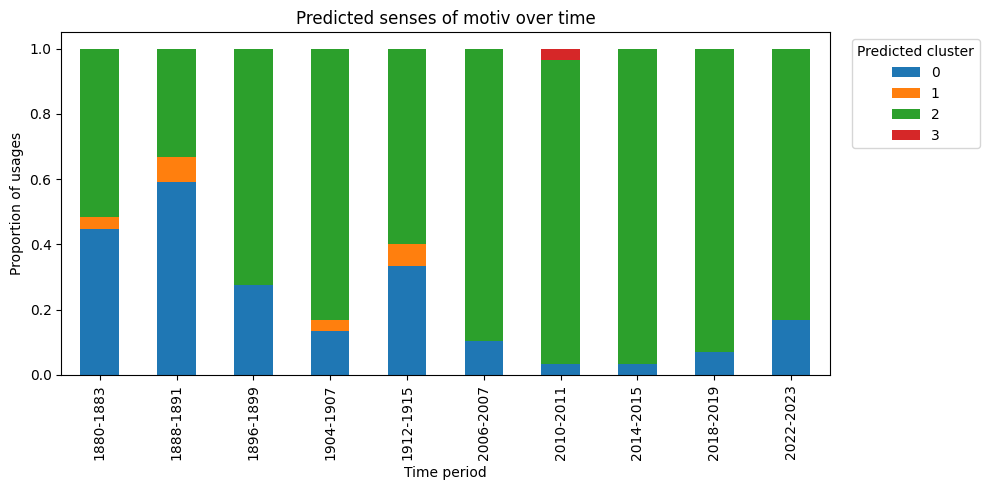

In [ ]:
import matplotlib.pyplot as plt

motiv_predictions = hierarchical_development.loc[
    hierarchical_development["word"] == "motiv"
].copy()

motiv_predictions["cluster"] = motiv_predictions["label"].apply(
    lambda labels: labels[0]
)

sense_counts = pd.crosstab(
    motiv_predictions["period_label"],
    motiv_predictions["cluster"]
).sort_index()

sense_proportions = sense_counts.div(
    sense_counts.sum(axis=1), axis=0
)

sense_proportions.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Predicted senses of motiv over time")
plt.xlabel("Time period")
plt.ylabel("Proportion of usages")
plt.legend(title="Predicted cluster", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

####Inspect examples from each predicted cluster to interpret the temporal pattern.

In [ ]:
motiv_examples = data_by_word["motiv"].merge(
    motiv_predictions[
        ["word", "period_label", "sentence_id", "cluster"]
    ],
    on=["word", "period_label", "sentence_id"],
    validate="one_to_one"
)

for cluster, rows in motiv_examples.groupby("cluster"):
    print(f"\nCluster {cluster} — {len(rows)} usages")

    examples = rows.sample(
        n=min(4, len(rows)),
        random_state=42
    )

    for _, row in examples.iterrows():
        print(f"{row['year']}: {row['text']}")


Cluster 0 — 63 usages
2006: 39.000 barn från fem år till femte klass ska avgöra om en ny barnspårvagn ska få djungel- , rymd- eller spök- motiv .
1881: Ett annat ledande motiv återfinnes i det stora , derpå följande recitativet , hvari Gurnemanz skildrar detta ridderskaps och Graal-templets uppkomst .
1915: Någon » midsommardans » af det slag , som man ser på konstnärernas motiv frän just denna till:ti ; .-i , n " i kan oc . "
2022: Mellan 2005 och 2009 tog Moll tusentals bilder från Tibbleberget och resultatet är nu fem panoramabilder , fem meter långa och en meter höga , med motiv från de fyra årstiderna i dagsljus samt en sommarnattsbild .

Cluster 1 — 6 usages
1889: I lagförslagets motiv frambålles , att man skall följa de ledande grundsatserna för den tyska kolo nialpolitik , som riksdagen gillade 1884 och 1885 .
1906: Stämman beslöt att som sin förklaring uttala , att den , vidhållande i alla delar pröfningsnämndens motiv , ansåg , att pröfningsnämndens beslut borde få bestå .
1

####Load multilingual BERT for a third embedding-model experiment.

In [ ]:
mbert_name = "google-bert/bert-base-multilingual-cased"

mbert_tokenizer = AutoTokenizer.from_pretrained(
    mbert_name, use_fast=True
)

mbert_model = AutoModel.from_pretrained(
    mbert_name
).to(device).eval()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


####Extract mBERT vectors for the target word in each sentence.

In [ ]:
def get_mbert_vector(row):
    text = row["text"]
    start = int(row["start"])
    end = int(row["end"])

    encoded = mbert_tokenizer(
        text,
        return_offsets_mapping=True,
        return_tensors="pt"
    )

    offsets = encoded.pop("offset_mapping")[0].tolist()

    target_tokens = []
    for i, (token_start, token_end) in enumerate(offsets):
        if token_end > token_start and token_start < end and token_end > start:
            target_tokens.append(i)

    if not target_tokens:
        raise ValueError(f"Target word not found: {row['sentence_id']}")

    if encoded["input_ids"].shape[1] > mbert_model.config.max_position_embeddings:
        raise ValueError(
            f"Sentence needs a shorter context window: {row['sentence_id']}"
        )

    encoded = encoded.to(device)

    with torch.no_grad():
        output = mbert_model(**encoded)

    target_vectors = output.last_hidden_state[0, target_tokens]
    vector = target_vectors.mean(dim=0)

    return vector.cpu().numpy()

####Generate mBERT embeddings for the tuning words.

In [ ]:
mbert_vectors_by_word = {}

for word in tqdm(tuning_words):
    vectors = []

    for _, row in data_by_word[word].iterrows():
        vectors.append(get_mbert_vector(row))

    mbert_vectors_by_word[word] = np.stack(vectors)

  0%|          | 0/7 [00:00<?, ?it/s]

####Evaluate mBERT with average-linkage hierarchical clustering on the tuning words.

In [ ]:
mbert_results = []

for cutoff in np.arange(0.1, 1.01, 0.1):
    prediction_parts = []
    cluster_counts = []

    for word in tuning_words:
        vectors = normalize(mbert_vectors_by_word[word])

        labels = AgglomerativeClustering(
            n_clusters=None,
            metric="cosine",
            linkage="average",
            distance_threshold=float(cutoff)
        ).fit_predict(vectors)

        cluster_counts.append(len(np.unique(labels)))

        predictions = data_by_word[word][
            ["word", "period_label", "sentence_id"]
        ].copy()
        predictions["label"] = [[int(label)] for label in labels]
        prediction_parts.append(predictions)

    predictions = pd.concat(prediction_parts, ignore_index=True)
    predictions.to_json(
        "mbert_tuning.jsonl", orient="records", lines=True
    )

    clustering, change = evaluate_subtask1(
        Path("tuning_all_gold.jsonl"),
        Path("mbert_tuning.jsonl")
    )

    mbert_results.append({
        "distance_cutoff": round(float(cutoff), 2),
        "1a_F1": clustering["fcubed"],
        "1b_Spearman": change,
        "mean_clusters": np.mean(cluster_counts)
    })

mbert_results = pd.DataFrame(mbert_results)
mbert_results

/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


,distance_cutoff,1a_F1,1b_Spearman,mean_clusters
0,0.1,0.057135,-0.014467,196.571429
1,0.2,0.116475,0.434111,113.285714
2,0.3,0.382096,0.289134,26.857143
3,0.4,0.652425,0.362507,4.714286
4,0.5,0.685005,0.440079,2.000000
5,0.6,0.707728,0.320382,1.428571
6,0.7,0.707650,0.320382,1.142857
7,0.8,0.707600,0.000000,1.000000
8,0.9,0.707600,0.000000,1.000000
9,1.0,0.707600,0.000000,1.000000


####Extract XLM-RoBERTa embeddings for the tuning words to compare embedding models using the same clustering method.

In [ ]:
xlmr_vectors_by_word = {}

for word in tqdm(tuning_words):
    vectors = []

    for _, row in data_by_word[word].iterrows():
        vectors.append(get_word_vector(row))

    xlmr_vectors_by_word[word] = np.stack(vectors)

  0%|          | 0/7 [00:00<?, ?it/s]

####Tune the hierarchical distance cutoff for XLM-RoBERTa and evaluate both metrics.

In [ ]:
xlmr_results = []

for cutoff in [
    0.002, 0.004, 0.006, 0.008, 0.010,
    0.012, 0.015, 0.020, 0.025, 0.030
]:
    prediction_parts = []
    cluster_counts = []

    for word in tuning_words:
        vectors = normalize(xlmr_vectors_by_word[word])

        labels = AgglomerativeClustering(
            n_clusters=None,
            metric="cosine",
            linkage="average",
            distance_threshold=cutoff
        ).fit_predict(vectors)

        cluster_counts.append(len(np.unique(labels)))

        predictions = data_by_word[word][
            ["word", "period_label", "sentence_id"]
        ].copy()
        predictions["label"] = [[int(label)] for label in labels]
        prediction_parts.append(predictions)

    predictions = pd.concat(prediction_parts, ignore_index=True)
    predictions.to_json(
        "xlmr_tuning.jsonl", orient="records", lines=True
    )

    clustering, change = evaluate_subtask1(
        Path("tuning_all_gold.jsonl"),
        Path("xlmr_tuning.jsonl")
    )

    xlmr_results.append({
        "distance_cutoff": round(float(cutoff), 3),
        "1a_F1": clustering["fcubed"],
        "1b_Spearman": change,
        "mean_clusters": np.mean(cluster_counts)
    })

xlmr_results = pd.DataFrame(xlmr_results)
xlmr_results

,distance_cutoff,1a_F1,1b_Spearman,mean_clusters
0,0.002,0.070292,0.546454,152.714286
1,0.004,0.241826,0.741071,57.714286
2,0.006,0.412018,0.710564,24.857143
3,0.008,0.503284,0.633340,13.285714
4,0.010,0.589068,0.702058,8.000000
5,0.012,0.635720,0.669818,5.428571
6,0.015,0.707587,0.554611,3.142857
7,0.020,0.705721,0.384987,1.857143
8,0.025,0.706317,0.212699,1.285714
9,0.030,0.707732,-0.169090,1.142857


####Inspect XLM-RoBERTa cosine distances to choose a more appropriate clustering-cutoff range.

In [ ]:
from sklearn.metrics import pairwise_distances

distance_summary = []

for word in tuning_words:
    vectors = normalize(xlmr_vectors_by_word[word])
    distances = pairwise_distances(vectors, metric="cosine")
    pairs = distances[np.triu_indices(len(vectors), k=1)]

    distance_summary.append({
        "word": word,
        "minimum": pairs.min(),
        "median": np.median(pairs),
        "90th_percentile": np.quantile(pairs, 0.90),
        "maximum": pairs.max()
    })

pd.DataFrame(distance_summary)

,word,minimum,median,90th_percentile,maximum
0,motiv,0.000376,0.009953,0.015483,0.036230
1,kvinna,0.000644,0.007636,0.011691,0.049524
2,fru,0.000646,0.008580,0.014934,0.033847
3,fröken,0.000000,0.007841,0.014165,0.025889
4,förort,0.000000,0.007896,0.012684,0.025736
5,skär,0.000637,0.010873,0.018279,0.032870
6,suga,0.000000,0.013419,0.029549,0.058292


####Extract XLM-RoBERTa embeddings for the reserved words to evaluate the candidate selected on the tuning set.

In [ ]:
for word in tqdm(heldout_words):
    vectors = []

    for _, row in data_by_word[word].iterrows():
        vectors.append(get_word_vector(row))

    xlmr_vectors_by_word[word] = np.stack(vectors)

  0%|          | 0/3 [00:00<?, ?it/s]

####Evaluate XLM-RoBERTa hierarchical clustering with cutoff 0.010 on the reserved words.

In [ ]:
prediction_parts = []

for word in heldout_words:
    vectors = normalize(xlmr_vectors_by_word[word])

    labels = AgglomerativeClustering(
        n_clusters=None,
        metric="cosine",
        linkage="average",
        distance_threshold=0.010
    ).fit_predict(vectors)

    predictions = data_by_word[word][
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in labels]
    prediction_parts.append(predictions)

xlmr_validation = pd.concat(prediction_parts, ignore_index=True)
xlmr_validation.to_json(
    "xlmr_validation.jsonl", orient="records", lines=True
)

xlmr_validation_scores, xlmr_validation_change = evaluate_subtask1(
    Path("heldout_all_gold.jsonl"),
    Path("xlmr_validation.jsonl")
)

print("XLM-RoBERTa 1a F1:", xlmr_validation_scores["fcubed"])
print("XLM-RoBERTa 1b Spearman:", xlmr_validation_change)

XLM-RoBERTa 1a F1: 0.7414627284833797
XLM-RoBERTa 1b Spearman: 0.5528905289052889


####Evaluate XLM-RoBERTa’s shared sense assignments for both Subtask 1a and 1b.

In [ ]:
prediction_parts = []

for word in sorted(data_by_word):
    vectors = normalize(xlmr_vectors_by_word[word])

    labels = AgglomerativeClustering(
        n_clusters=None,
        metric="cosine",
        linkage="average",
        distance_threshold=0.010
    ).fit_predict(vectors)

    predictions = data_by_word[word][
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in labels]
    prediction_parts.append(predictions)

xlmr_development = pd.concat(prediction_parts, ignore_index=True)
xlmr_development.to_json(
    "development_xlmr.jsonl", orient="records", lines=True
)

xlmr_scores, xlmr_change = evaluate_subtask1(
    Path("gold/SV/subtask1.jsonl"),
    Path("development_xlmr.jsonl")
)

pd.DataFrame([
    {
        "model": "XL-LEXEME",
        "1a_F1": hierarchical_scores["fcubed"],
        "1b_Spearman": hierarchical_change
    },
    {
        "model": "XLM-RoBERTa",
        "1a_F1": xlmr_scores["fcubed"],
        "1b_Spearman": xlmr_change
    }
])

,model,1a_F1,1b_Spearman
0,XL-LEXEME,0.810829,0.562016
1,XLM-RoBERTa,0.634787,0.641340


####Compare the selected system with the baseline and the alternative XLM-RoBERTa system on all development words.

In [ ]:
final_comparison = pd.DataFrame([
    {
        "approach": "Single-cluster baseline",
        "1a_F1": baseline_scores["fcubed"],
        "1b_Spearman": np.nan
    },
    {
        "approach": "XL-LEXEME + hierarchical, cutoff 0.4",
        "1a_F1": hierarchical_scores["fcubed"],
        "1b_Spearman": hierarchical_change
    },
    {
        "approach": "XLM-RoBERTa + hierarchical, cutoff 0.010",
        "1a_F1": xlmr_scores["fcubed"],
        "1b_Spearman": xlmr_change
    }
])

final_comparison.to_csv(
    "subtask1_development_comparison.csv", index=False
)

final_comparison

,approach,1a_F1,1b_Spearman
0,Single-cluster baseline,0.756342,NaN
1,"XL-LEXEME + hierarchical, cutoff 0.4",0.810829,0.562016
2,"XLM-RoBERTa + hierarchical, cutoff 0.010",0.634787,0.641340


####Save embeddings and their matching usage rows for future experiments.

In [ ]:
from zipfile import ZipFile

cache_folder = Path("subtask1_embedding_cache")
cache_folder.mkdir(exist_ok=True)

for word, rows in data_by_word.items():
    rows[["word", "period_label", "sentence_id", "text", "start", "end"]].to_json(
        cache_folder / f"{word}_usages.jsonl",
        orient="records",
        lines=True,
        force_ascii=False
    )

for model_name, embeddings in [
    ("xl_lexeme", vectors_by_word),
    ("xlmr", xlmr_vectors_by_word),
    ("mbert", mbert_vectors_by_word)
]:
    np.savez_compressed(
        cache_folder / f"{model_name}_vectors.npz",
        **embeddings
    )

with ZipFile("subtask1_embedding_cache.zip", "w") as archive:
    for file in cache_folder.iterdir():
        archive.write(file, arcname=file.name)

print("Saved subtask1_embedding_cache.zip")

Saved subtask1_embedding_cache.zip


In [ ]:
import requests
from io import BytesIO
from zipfile import ZipFile, is_zipfile

url = "https://www.codabench.org/datasets/download/id/936979/"
response = requests.get(url)
response.raise_for_status()

sample_file = BytesIO(response.content)

if not is_zipfile(sample_file):
    raise ValueError(
        "The download did not return a ZIP. "
        "Download the example through your logged-in Codabench account."
    )

with ZipFile(sample_file) as archive:
    for name in archive.namelist():
        print(name)

SV_subtask1.jsonl
SV_subtask2.jsonl


In [ ]:
sample_file.seek(0)

with ZipFile(sample_file) as archive:
    with archive.open("SV_subtask1.jsonl") as file:
        example = json.loads(file.readline())

print(example)

{'word': 'kvinna', 'sentence_id': '137d9286_62_69', 'label': [0]}


####Export the selected Subtask 1 predictions in the competition’s submission format.

In [ ]:
submission = hierarchical_development[
    ["word", "sentence_id", "label"]
].copy()

assert not submission.duplicated(["word", "sentence_id"]).any()

submission.to_json(
    "SV_subtask1.jsonl",
    orient="records",
    lines=True,
    force_ascii=False
)

print("Saved SV_subtask1.jsonl")
print("Total predictions:", len(submission))

Saved SV_subtask1.jsonl
Total predictions: 1983


####Test density-based clustering, assigning each outlier its own label so unrelated outliers are not grouped together.

In [ ]:
from sklearn.cluster import HDBSCAN

def get_hdbscan_labels(vectors, min_cluster_size, min_samples):
    vectors = normalize(vectors)

    labels = HDBSCAN(
        min_cluster_size=min_cluster_size,
        min_samples=min_samples,
        metric="cosine",
        algorithm="brute",
        allow_single_cluster=True
    ).fit_predict(vectors)

    outliers = np.flatnonzero(labels == -1)
    next_label = int(labels.max()) + 1

    for position in outliers:
        labels[position] = next_label
        next_label += 1

    return labels, len(outliers)

####Compare HDBSCAN settings for sense clustering and semantic change, recording how many usages are treated as outliers.

In [ ]:
hdbscan_results = []

for min_cluster_size in [3, 5, 10, 15]:
    for min_samples in [2, 5]:
        prediction_parts = []
        cluster_counts = []
        total_outliers = 0

        for word in tuning_words:
            labels, outlier_count = get_hdbscan_labels(
                vectors_by_word[word],
                min_cluster_size,
                min_samples
            )

            total_outliers += outlier_count
            cluster_counts.append(len(np.unique(labels)))

            predictions = data_by_word[word][
                ["word", "period_label", "sentence_id"]
            ].copy()
            predictions["label"] = [[int(label)] for label in labels]
            prediction_parts.append(predictions)

        predictions = pd.concat(prediction_parts, ignore_index=True)
        predictions.to_json(
            "hdbscan_tuning.jsonl", orient="records", lines=True
        )

        clustering, change = evaluate_subtask1(
            Path("tuning_all_gold.jsonl"),
            Path("hdbscan_tuning.jsonl")
        )

        hdbscan_results.append({
            "min_cluster_size": min_cluster_size,
            "min_samples": min_samples,
            "1a_F1": clustering["fcubed"],
            "1b_Spearman": change,
            "mean_clusters": np.mean(cluster_counts),
            "outlier_usages": total_outliers
        })

hdbscan_results = pd.DataFrame(hdbscan_results)
hdbscan_results

,min_cluster_size,min_samples,1a_F1,1b_Spearman,mean_clusters,outlier_usages
0,3,2,0.663561,0.137322,40.857143,262
1,3,5,0.427965,-0.221643,94.571429,650
2,5,2,0.618820,-0.165301,48.000000,323
3,5,5,0.450918,-0.199751,89.142857,613
4,10,2,0.503704,-0.334818,77.142857,529
5,10,5,0.446966,-0.214469,87.714286,605
6,15,2,0.499009,-0.346789,82.428571,567
7,15,5,0.411063,-0.256563,99.857143,690


####Assign HDBSCAN outliers to the nearest detected cluster instead of creating singleton clusters.

In [ ]:
def get_hdbscan_reassigned_labels(
    vectors, min_cluster_size, min_samples
):
    vectors = normalize(vectors)

    labels = HDBSCAN(
        min_cluster_size=min_cluster_size,
        min_samples=min_samples,
        metric="cosine",
        algorithm="brute",
        allow_single_cluster=True
    ).fit_predict(vectors)

    outliers = labels == -1
    outlier_count = int(outliers.sum())
    clusters = np.unique(labels[~outliers])

    if len(clusters) == 0:
        return np.zeros(len(vectors), dtype=int), outlier_count

    if outlier_count > 0:
        centers = np.stack([
            vectors[labels == cluster].mean(axis=0)
            for cluster in clusters
        ])
        similarities = vectors[outliers] @ normalize(centers).T
        labels[outliers] = clusters[similarities.argmax(axis=1)]

    return labels, outlier_count

####Test whether assigning outliers to nearby clusters improves HDBSCAN’s results.

In [ ]:
reassigned_results = []

for min_cluster_size in [3, 5, 10, 15]:
    for min_samples in [2, 5]:
        prediction_parts = []
        cluster_counts = []
        total_outliers = 0

        for word in tuning_words:
            labels, outlier_count = get_hdbscan_reassigned_labels(
                vectors_by_word[word],
                min_cluster_size,
                min_samples
            )

            total_outliers += outlier_count
            cluster_counts.append(len(np.unique(labels)))

            predictions = data_by_word[word][
                ["word", "period_label", "sentence_id"]
            ].copy()
            predictions["label"] = [[int(label)] for label in labels]
            prediction_parts.append(predictions)

        predictions = pd.concat(prediction_parts, ignore_index=True)
        predictions.to_json(
            "hdbscan_reassigned_tuning.jsonl",
            orient="records",
            lines=True
        )

        clustering, change = evaluate_subtask1(
            Path("tuning_all_gold.jsonl"),
            Path("hdbscan_reassigned_tuning.jsonl")
        )

        reassigned_results.append({
            "min_cluster_size": min_cluster_size,
            "min_samples": min_samples,
            "1a_F1": clustering["fcubed"],
            "1b_Spearman": change,
            "mean_clusters": np.mean(cluster_counts),
            "outlier_usages": total_outliers
        })

reassigned_results = pd.DataFrame(reassigned_results)
reassigned_results

,min_cluster_size,min_samples,1a_F1,1b_Spearman,mean_clusters,outlier_usages
0,3,2,0.737840,0.267941,3.428571,262
1,3,5,0.745220,0.256885,1.714286,650
2,5,2,0.741666,0.199549,1.857143,323
3,5,5,0.754030,0.292020,1.571429,613
4,10,2,0.733751,0.172242,1.571429,529
5,10,5,0.747692,0.238318,1.285714,605
6,15,2,0.737220,0.170046,1.428571,567
7,15,5,0.747692,0.238318,1.285714,690


####Prepare and scale distances from both embedding models before combining them.

In [ ]:
from sklearn.metrics import pairwise_distances

lexeme_distances = {}
xlmr_distances = {}

lexeme_pairs = []
xlmr_pairs = []

for word in tuning_words:
    lexeme_vectors = vectors_by_word[word]
    xlmr_vectors = xlmr_vectors_by_word[word]

    assert len(lexeme_vectors) == len(xlmr_vectors) == len(data_by_word[word])

    lexeme_matrix = pairwise_distances(
        normalize(lexeme_vectors), metric="cosine"
    )
    xlmr_matrix = pairwise_distances(
        normalize(xlmr_vectors), metric="cosine"
    )

    np.fill_diagonal(lexeme_matrix, 0)
    np.fill_diagonal(xlmr_matrix, 0)

    lexeme_distances[word] = lexeme_matrix
    xlmr_distances[word] = xlmr_matrix

    upper_triangle = np.triu_indices(len(lexeme_vectors), k=1)
    lexeme_pairs.append(lexeme_matrix[upper_triangle])
    xlmr_pairs.append(xlmr_matrix[upper_triangle])

lexeme_typical = np.median(np.concatenate(lexeme_pairs))
xlmr_typical = np.median(np.concatenate(xlmr_pairs))

if xlmr_typical <= 0:
    raise ValueError("Cannot scale distances with a zero median.")

xlmr_distance_scale = lexeme_typical / xlmr_typical

print("XLM-RoBERTa distance multiplier:", xlmr_distance_scale)

XLM-RoBERTa distance multiplier: 13.111703


####Compare blends of XL-LEXEME and XLM-RoBERTa distances using hierarchical clustering.

In [ ]:
blend_results = []

for lexeme_weight in [0.0, 0.25, 0.50, 0.75, 1.0]:
    for cutoff in [0.10, 0.15, 0.20, 0.30, 0.40, 0.50]:
        prediction_parts = []
        cluster_counts = []

        for word in tuning_words:
            distances = (
                lexeme_weight * lexeme_distances[word]
                + (1 - lexeme_weight)
                * xlmr_distance_scale
                * xlmr_distances[word]
            )

            distances = np.maximum(distances, 0)
            distances = (distances + distances.T) / 2
            np.fill_diagonal(distances, 0)

            labels = AgglomerativeClustering(
                n_clusters=None,
                metric="precomputed",
                linkage="average",
                distance_threshold=cutoff
            ).fit_predict(distances)

            cluster_counts.append(len(np.unique(labels)))

            predictions = data_by_word[word][
                ["word", "period_label", "sentence_id"]
            ].copy()
            predictions["label"] = [[int(label)] for label in labels]
            prediction_parts.append(predictions)

        predictions = pd.concat(prediction_parts, ignore_index=True)
        predictions.to_json(
            "blend_tuning.jsonl", orient="records", lines=True
        )

        clustering, change = evaluate_subtask1(
            Path("tuning_all_gold.jsonl"),
            Path("blend_tuning.jsonl")
        )

        blend_results.append({
            "lexeme_weight": lexeme_weight,
            "cutoff": cutoff,
            "1a_F1": clustering["fcubed"],
            "1b_Spearman": change,
            "mean_clusters": np.mean(cluster_counts)
        })

blend_results = pd.DataFrame(blend_results)
blend_results.sort_values("1a_F1", ascending=False).head(15)

/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/content/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


,lexeme_weight,cutoff,1a_F1,1b_Spearman,mean_clusters
28,1.00,0.4,0.773565,0.582533,4.142857
15,0.50,0.3,0.771778,0.592578,3.285714
21,0.75,0.3,0.765045,0.488985,4.714286
22,0.75,0.4,0.762938,0.503585,2.714286
29,1.00,0.5,0.759511,0.477415,2.428571
27,1.00,0.3,0.758880,0.551003,6.142857
8,0.25,0.2,0.744879,0.549214,5.142857
14,0.50,0.2,0.740827,0.539298,7.285714
26,1.00,0.2,0.727784,0.630932,10.714286
16,0.50,0.4,0.727017,0.323765,1.857143


####Evaluate the blended-distance candidate on the reserved words using the scaling learned from the tuning words.

In [ ]:
blend_prediction_parts = []

for word in heldout_words:
    lexeme_matrix = pairwise_distances(
        normalize(vectors_by_word[word]), metric="cosine"
    )
    xlmr_matrix = pairwise_distances(
        normalize(xlmr_vectors_by_word[word]), metric="cosine"
    )

    distances = (
        0.5 * lexeme_matrix
        + 0.5 * xlmr_distance_scale * xlmr_matrix
    )

    distances = np.maximum(distances, 0)
    distances = (distances + distances.T) / 2
    np.fill_diagonal(distances, 0)

    labels = AgglomerativeClustering(
        n_clusters=None,
        metric="precomputed",
        linkage="average",
        distance_threshold=0.3
    ).fit_predict(distances)

    predictions = data_by_word[word][
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in labels]
    blend_prediction_parts.append(predictions)

blend_validation = pd.concat(
    blend_prediction_parts, ignore_index=True
)
blend_validation.to_json(
    "blend_validation.jsonl", orient="records", lines=True
)

blend_scores, blend_change = evaluate_subtask1(
    Path("heldout_all_gold.jsonl"),
    Path("blend_validation.jsonl")
)

print("Blended model 1a F1:", blend_scores["fcubed"])
print("Blended model 1b Spearman:", blend_change)

Blended model 1a F1: 0.8987301821408433
Blended model 1b Spearman: 0.3095262886926845


####Evaluate the fixed 50/50 distance blend across all development words.

In [ ]:
blend_parts = []

for word in sorted(data_by_word):
    lexeme_matrix = pairwise_distances(
        normalize(vectors_by_word[word]), metric="cosine"
    )
    xlmr_matrix = pairwise_distances(
        normalize(xlmr_vectors_by_word[word]), metric="cosine"
    )

    distances = (
        0.5 * lexeme_matrix
        + 0.5 * xlmr_distance_scale * xlmr_matrix
    )

    distances = np.maximum(distances, 0)
    distances = (distances + distances.T) / 2
    np.fill_diagonal(distances, 0)

    labels = AgglomerativeClustering(
        n_clusters=None,
        metric="precomputed",
        linkage="average",
        distance_threshold=0.3
    ).fit_predict(distances)

    predictions = data_by_word[word][
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in labels]
    blend_parts.append(predictions)

blend_development = pd.concat(blend_parts, ignore_index=True)
blend_development.to_json(
    "development_blended.jsonl", orient="records", lines=True
)

blend_development_scores, blend_development_change = evaluate_subtask1(
    Path("gold/SV/subtask1.jsonl"),
    Path("development_blended.jsonl")
)

pd.DataFrame([
    {
        "approach": "XL-LEXEME alone",
        "1a_F1": hierarchical_scores["fcubed"],
        "1b_Spearman": hierarchical_change
    },
    {
        "approach": "50/50 blend",
        "1a_F1": blend_development_scores["fcubed"],
        "1b_Spearman": blend_development_change
    }
])

,approach,1a_F1,1b_Spearman
0,XL-LEXEME alone,0.810829,0.562016
1,50/50 blend,0.809864,0.598987


## Subtask 2a: John

###LaBSE embeddings with cosine similarity and a tuned threshold

In [ ]:
%pip install -q sentence-transformers scikit-learn

####Imports

In [ ]:
import pandas as pd
import numpy as np
import torch

from pathlib import Path
from sentence_transformers import SentenceTransformer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import f1_score, precision_score, recall_score

####Load the usages, definitions, and development labels

In [ ]:
folder = Path("semantic-change-over-time/data/raw/development-swedish")

usages = pd.read_json(folder / "usages.jsonl", lines=True)
gold = pd.read_json(folder / "subtask2.jsonl", lines=True)

definitions_path = folder / "definitions.jsonl"

if definitions_path.suffix == ".jsonl":
    definitions = pd.read_json(definitions_path, lines=True)
else:
    definitions = pd.read_json(definitions_path)

definitions.head()

,word,definition
0,kvinna,Generell beteckning för kvinnokönet eller samt...
1,skär,"Klar, blank, skir; ren, ljus och vacker; skina..."
2,fröken,"Gift eller ogift yrkesutövande kvinna, företrä..."
3,dumpa,Låta något falla; lägga eller sänka ner
4,exportera,Föra ut en produkt ur ett land (till ett annat...


####Match each usage with its target definition and label

In [ ]:
target_definitions = definitions[["word", "definition"]].copy()

data = gold[["word", "sentence_id", "label"]].merge(
    usages[["word", "sentence_id", "text", "start", "end"]],
    on=["word", "sentence_id"],
    how="left",
    validate="one_to_one"
)

data = data.merge(
    target_definitions,
    on="word",
    how="left",
    validate="many_to_one"
)

if data[["text", "definition"]].isna().any().any():
    raise ValueError("Some usages or target definitions are missing.")

data["label"] = data["label"].astype(int)

if not data["label"].isin([0, 1]).all():
    raise ValueError("Expected binary labels: 0 or 1.")

data = data.reset_index(drop=True)

data[["word", "text", "definition", "label"]].head()

,word,text,definition,label
0,kvinna,nesliga lif medelst sjelfmord ; och ett stort ...,Generell beteckning för kvinnokönet eller samt...,0
1,kvinna,"— Jag sov ; jag väcktes av en kylande känsla ,...",Generell beteckning för kvinnokönet eller samt...,0
2,kvinna,"orden , så mycken fasthet öfver den gamla kvin...",Generell beteckning för kvinnokönet eller samt...,0
3,kvinna,Dessa klubbar ha anordnat sällskapliga samkväm...,Generell beteckning för kvinnokönet eller samt...,0
4,kvinna,Den avvisningshotade eritranska kvinnan Abiba ...,Generell beteckning för kvinnokönet eller samt...,0


####Create short contexts around the target word

In [ ]:
def get_context(row):
    text = row["text"]
    start = int(row["start"])
    end = int(row["end"])

    left = max(0, start - 120)
    right = min(len(text), end + 120)

    return text[left:right].strip()


data["context"] = data.apply(get_context, axis=1)

display(data[["word", "context", "definition"]].head())

,word,context,definition
0,kvinna,nesliga lif medelst sjelfmord ; och ett stort ...,Generell beteckning för kvinnokönet eller samt...
1,kvinna,"— Jag sov ; jag väcktes av en kylande känsla ,...",Generell beteckning för kvinnokönet eller samt...
2,kvinna,"orden , så mycken fasthet öfver den gamla kvin...",Generell beteckning för kvinnokönet eller samt...
3,kvinna,Dessa klubbar ha anordnat sällskapliga samkväm...,Generell beteckning för kvinnokönet eller samt...
4,kvinna,Den avvisningshotade eritranska kvinnan Abiba ...,Generell beteckning för kvinnokönet eller samt...


####Generate LaBSE embeddings

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

labse = SentenceTransformer(
    "sentence-transformers/LaBSE",
    device=device
)

modules.json:   0%|          | 0.00/461 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/2.02k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/804 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.88GB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/114 [00:00<?, ?B/s]

2_Dense/model.safetensors: reconstructing file:   0%|          |  0.00B / 2.36MB            

2_Dense/model.safetensors: downloading bytes:           |  0.00B            

In [ ]:
all_texts = (
    data["context"].tolist()
    + data["definition"].drop_duplicates().tolist()
)

lengths = [
    len(labse.tokenizer.encode(text))
    for text in all_texts
]

In [ ]:
context_vectors = labse.encode(
    data["context"].tolist(),
    batch_size=32,
    normalize_embeddings=True,
    show_progress_bar=True
)

definition_texts = data["definition"].drop_duplicates().tolist()

definition_vectors = labse.encode(
    definition_texts,
    batch_size=32,
    normalize_embeddings=True,
    show_progress_bar=True
)

definition_lookup = dict(
    zip(definition_texts, definition_vectors)
)

paired_definition_vectors = np.stack([
    definition_lookup[text]
    for text in data["definition"]
])

Batches:   0%|          | 0/62 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

####Calculate similarity scores

In [ ]:
data["similarity"] = np.sum(
    context_vectors * paired_definition_vectors,
    axis=1
)

data[["word", "context", "definition", "similarity", "label"]].head()

,word,context,definition,similarity,label
0,kvinna,nesliga lif medelst sjelfmord ; och ett stort ...,Generell beteckning för kvinnokönet eller samt...,0.323493,0
1,kvinna,"— Jag sov ; jag väcktes av en kylande känsla ,...",Generell beteckning för kvinnokönet eller samt...,0.390163,0
2,kvinna,"orden , så mycken fasthet öfver den gamla kvin...",Generell beteckning för kvinnokönet eller samt...,0.415619,0
3,kvinna,Dessa klubbar ha anordnat sällskapliga samkväm...,Generell beteckning för kvinnokönet eller samt...,0.457884,0
4,kvinna,Den avvisningshotade eritranska kvinnan Abiba ...,Generell beteckning för kvinnokönet eller samt...,0.411359,0


####Separate threshold tuning from evaluation

In [ ]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

tune_indices, test_indices = next(
    splitter.split(data, groups=data["word"])
)

tune_data = data.iloc[tune_indices].copy()
test_data = data.iloc[test_indices].copy()

print("Tuning words:", tune_data["word"].unique())
print("Held-out words:", test_data["word"].unique())

In [ ]:
def average_word_f1(frame, predictions):
    results = frame[["word", "label"]].copy()
    results["prediction"] = np.asarray(predictions)

    scores = []

    for word, group in results.groupby("word"):
        score = f1_score(
            group["label"],
            group["prediction"],
            zero_division=0
        )
        scores.append(score)

    return np.mean(scores)

In [ ]:
threshold_results = []

for threshold in np.linspace(-1, 1, 201):
    predictions = (
        tune_data["similarity"] >= threshold
    ).astype(int)

    score = average_word_f1(tune_data, predictions)

    threshold_results.append({
        "threshold": threshold,
        "average_f1": score
    })

threshold_results = pd.DataFrame(threshold_results)

best_result = threshold_results.loc[
    threshold_results["average_f1"].idxmax()
]

best_threshold = float(best_result["threshold"])

print("Selected threshold:", best_threshold)
print("Tuning Average F1:", best_result["average_f1"])

####Evaluate against baseline (all 1s)

In [ ]:
test_predictions = (
    test_data["similarity"] >= best_threshold
).astype(int).to_numpy()

baseline_predictions = np.ones(len(test_data), dtype=int)

comparison = []

for name, predictions in [
    ("All-ones baseline", baseline_predictions),
    ("LaBSE + threshold", test_predictions)
]:
    comparison.append({
        "method": name,
        "average_word_f1": average_word_f1(
            test_data, predictions
        ),
        "precision_pooled": precision_score(
            test_data["label"], predictions, zero_division=0
        ),
        "recall_pooled": recall_score(
            test_data["label"], predictions, zero_division=0
        )
    })

pd.DataFrame(comparison)

#### some simple eda - main sense and stuff (ty)

##### correct ones and sens #

In [ ]:
import pandas as pd

answers = pd.read_json("semantic-change-over-time/data/raw/development-swedish/subtask1.jsonl", lines=True)
answers["sense"] = answers["label"].str[0]
answers.head()

#### seeing num of seses of each word and how common it is  & summary - by most mixed/jumbled to most centered on one sense

In [ ]:
all_senses = answers.explode("label")
counts = all_senses.groupby("word")["label"].value_counts()
sentences = answers["word"].value_counts()

summary = pd.DataFrame({
    "num_senses": all_senses.groupby("word")["label"].nunique(),
    "top_share": (counts.groupby("word").max() / sentences).round(2)
})
summary.sort_values("top_share")

#### subtask 2 - logistic regression (ty)

##### loading definitions/ right answers

In [ ]:
import pandas as pd

s2 = pd.read_json("semantic-change-over-time/data/raw/development-swedish/subtask2.jsonl", lines=True)
defs = pd.read_json("semantic-change-over-time/data/raw/development-swedish/definitions.jsonl", lines=True)
defs

,word,definition
0,kvinna,Generell beteckning för kvinnokönet eller samt...
1,skär,"Klar, blank, skir; ren, ljus och vacker; skina..."
2,fröken,"Gift eller ogift yrkesutövande kvinna, företrä..."
3,dumpa,Låta något falla; lägga eller sänka ner
4,exportera,Föra ut en produkt ur ett land (till ett annat...
5,fru,"Maka, hustru (oavsett klass)"
6,herre,Manlig överklassperson med betoning på privile...
7,förort,En invandrartät stadsdel som ligger utanför in...
8,suga,Dra in vätska eller gas i munnen genom åstadko...
9,motiv,Ämne för konstnärlig fram­ställning in­om bild...


##### % of "yes" answers per word (6% to 95%)

In [ ]:
yes_share = s2.groupby("word")["label"].mean().round(2)
yes_share.sort_values()

,label
word,
fröken,0.06
herre,0.07
motiv,0.18
suga,0.19
kvinna,0.23
skär,0.28
dumpa,0.31
förort,0.49
fru,0.89


##### saving john's labse sim scores

In [ ]:
scores = data[["word", "sentence_id", "similarity", "label"]]
scores.to_csv("labse_scores.csv", index=False)
scores.head()

,word,sentence_id,similarity,label
0,kvinna,137d9286_62_69,0.323493,0
1,kvinna,b382a5e9_92_98,0.390163,0
2,kvinna,28ffffe7_42_50,0.415619,0
3,kvinna,3754909a_117_124,0.457884,0
4,kvinna,59ebb00_32_39,0.411359,0


##### getting backup of scores just in case

In [ ]:
from google.colab import files
files.download("labse_scores.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##### reloading saved labse scores

In [1]:
import pandas as pd
scores = pd.read_csv("labse_scores.csv")

##### do yes sentences score higher than no sentences? (avg similarity per word)

In [2]:
avg = scores.pivot_table(index="word", columns="label", values="similarity").round(3)
avg.columns = ["avg_no", "avg_yes"]
avg["difference"] = avg["avg_yes"] - avg["avg_no"]
avg.sort_values("difference")

,avg_no,avg_yes,difference
word,,,
exportera,0.491,0.478,-0.013
dumpa,0.416,0.408,-0.008
herre,0.358,0.360,0.002
suga,0.399,0.412,0.013
förort,0.311,0.325,0.014
fröken,0.355,0.385,0.030
skär,0.356,0.389,0.033
kvinna,0.409,0.444,0.035
motiv,0.234,0.276,0.042


the gap between yes and no is pretty small, so it's easy for us to conclude that labse similarity barely tells them apart